# create MCP client

In [1]:
import sys
import asyncio
import io

# Force Windows to use the Proactor Event Loop for async subprocesses
if sys.platform == "win32":
    asyncio.set_event_loop_policy(asyncio.WindowsProactorEventLoopPolicy())

# Patch Jupyter's OutStream to prevent the fileno crash during process fallback
if hasattr(sys.stderr, "fileno"):
    try:
        sys.stderr.fileno()
    except io.UnsupportedOperation:
        sys.stderr.fileno = lambda: 2

In [2]:
import os 
from dotenv import load_dotenv
load_dotenv()
#OPENWEATHER_API_KEY = os.getenv("WEATHER_API_KEY")
#os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")

True

In [3]:
import warnings 
warnings.filterwarnings(action="ignore", category=DeprecationWarning)


In [4]:
from langchain.chat_models import init_chat_model

# Groq Models
# Pass groq_api_key explicitly or set GROQ_API_KEY in environment variables
model_llama = init_chat_model("llama-3.3-70b-versatile", model_provider="groq")

# For Qwen on Groq, use valid model tags like qwen-2.5-32b or qwen-2.5-coder-32b
model_qwen = init_chat_model("qwen-2.5-32b", model_provider="groq")

# Google Gemini Model
# Pass google_api_key explicitly or set GOOGLE_API_KEY in environment variables
model_gem = init_chat_model("gemini-2.5-flash", model_provider="google_genai")

In [20]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="llama-3.1-8b-instant",  # or "llama3-70b-8192"
    temperature=0
)

In [5]:
#create mcp client
import pywintypes
from langchain_mcp_adapters.client import MultiServerMCPClient

In [6]:
client = MultiServerMCPClient({
    "weather_mcp": {
        "transport": "stdio",
        "command": "cmd.exe",
        "args": [
            "/c",
            "open-meteo-mcp-server"
        ]
    },
})

In [7]:
tools = await client.get_tools()

In [8]:
for tool in tools:
    print(tool.name)
    print(tool.description)
    print(tool.args_schema)

weather_forecast
Get weather forecast data for coordinates using Open-Meteo API. Supports hourly and daily data with various weather variables. When no `models` parameter is provided, the API automatically selects the best model for the given location (recommended). Only one model per request is supported — for multi-model comparison, use provider-specific tools with parallel calls.
{'$schema': 'http://json-schema.org/draft-07/schema#', 'type': 'object', 'properties': {'latitude': {'type': 'number', 'minimum': -90, 'maximum': 90}, 'longitude': {'type': 'number', 'minimum': -180, 'maximum': 180}, 'hourly': {'type': 'array', 'items': {'anyOf': [{'type': 'string', 'enum': ['temperature_2m', 'relative_humidity_2m', 'dewpoint_2m', 'dew_point_2m', 'apparent_temperature', 'precipitation_probability', 'precipitation', 'rain', 'showers', 'snowfall', 'snow_depth', 'weather_code', 'pressure_msl', 'surface_pressure', 'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'visibil

In [9]:
prompt = """You are a helpful MCP assistant. Use MCP weather tools for giving a response for weather related queries. 
        For others, answer on your own."""

In [34]:
from langchain.agents import create_agent
agent = create_agent(
    model= llm,
    tools = tools,
    system_prompt = prompt
)

In [17]:
user_query = """Answer the following questions in brief
            - What is the wather in Peoria, IL, USA today?  
            """

In [33]:
from langchain.chat_models import init_chat_model

llm = init_chat_model("gemini-3.6-flash", model_provider="google_genai")

In [26]:
import warnings

# Suppress LangChain's schema key warnings for Gemini/OpenAPI
warnings.filterwarnings("ignore", category=UserWarning, message=".*not supported in schema, ignoring.*")

In [35]:
def clean_schema(schema: dict) -> dict:
    """Recursively strip unsupported JSON Schema keys for Gemini compatibility."""
    if not isinstance(schema, dict):
        return schema
    
    # Keys that trigger Gemini / OpenAPI schema warnings
    unsupported_keys = {"$schema", "additionalProperties"}
    cleaned = {k: clean_schema(v) for k, v in schema.items() if k not in unsupported_keys}
    return cleaned

# Clean args_schema for every MCP tool
for t in tools:
    if hasattr(t, "args_schema") and isinstance(t.args_schema, dict):
        t.args_schema = clean_schema(t.args_schema)

In [37]:
from langchain.messages import HumanMessage
try: 
    response = await agent.ainvoke({
        "messages":[
            HumanMessage(content=user_query)
        ]
    })
except Exception as e:
    raise RuntimeError(f"Invoke error, {e}")

In [38]:
print(response["messages"][-1].content)

[{'type': 'text', 'text': '**Current Weather in Peoria, IL, USA:**\n\n* **Conditions:** Clear / Sunny\n* **Temperature:** 58°F (Feels like 54°F)\n* **High / Low:** High of 64°F / Low of 35°F\n* **Humidity:** 56%\n* **Wind:** ~5 mph (Gusts up to 8 mph)\n* **Precipitation Chance:** 0%', 'extras': {'signature': 'ErIDCq8DAWkUfRNB0gANYG0nx1kb/Y7jl9Sx+8BlXDgx+DsNST3G9I4hw80Nr1MvD4JH4YbD8KGYKuweQo/VH3yOOY+0tjP8OX9O+/Kt6A/ZjLv0i813crV4lIInHLmu1h7PQI/USNfbmFrlHxBICl4kVwIRcE2djPYPSbuu6lQ5bOkIu2MhS7rOnQleKw5/aPLcSXXP2DHMcdaUcaE6dneobYSNzpqHffnP4AVffE48leUV3UjYKmvzY6f7Ohv8u+PseDIP6xh3lbC8kkkibz+it3Jqc/lTf/lvFDs6ro8j0WbF8EyqrTLDqL3DMXK6GUxixAuJiY/VojWvSrsxQKPpW0A+l51WRSM4UFNLuQgMqK5WQEGLIjRbjhtKK6a+6eZ/CTyaBhBfv1SXNoZVVfaiGaKmQjLQ1+m+/hL3gfMzv377OrO62CnxSETjwIXk+YbUctfhXdQrdLKMYkmS/sf3wjns33IowreEC3/q+U3ugvG6ZUWAIhCzuk0ZiV8xDK/QlIRje4843E8pkAEUyGrv1pnwiL/XueTFpnae1o9ZpvXj3Hk8gkYU16NOVItAjoS+DuY='}}]


# last class stuff

In [ ]:
import os 
from dotenv import load_dotenv
load_dotenv()
OPENWEATHER_API_KEY = os.getenv("WEATHER_API_KEY")
os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")

In [ ]:
import warnings 
warnings.filterwarnings(action="ignore", category=DeprecationWarning)


In [ ]:
from langchain.chat_models import init_chat_model
model = init_chat_model(model="openai/gpt-oss-120b", model_provider="groq")
model_fallback1 = init_chat_model(model="qwen/qwen3.8-27b", model_provider="groq")


In [ ]:
from typing_extensions import TypedDict
from pydantic import BaseModel, Field
from typing import Literal 

class ResearchAssistant(TypedDict):
    user_query:str
    routing:list[str]

    weather_generation:str
    web_generation:str
    #TODO: Add RAG_generation state
    synthesizer:str
    RAG_generation:str

In [ ]:
initial_state = {
    "user_query":"""Weather in Peoria. Top news today in USA. US Midterm Election Results 2026. What is Langgraph? """, 
}

In [ ]:
class RoutingDecision(BaseModel):
    routes: list[Literal["web", "weather", "RAG"]] = Field(
        description=(
            "Return every applicable route. Use web for news and internet search, "
            "weather for weather requests, and RAG for LangChain, LangGraph, "
            "and agent questions. Return an empty list if none applies."
        )
    )

In [ ]:
model_routing = model.with_structured_output(RoutingDecision)


In [ ]:
from langchain.messages import HumanMessage, SystemMessage


In [ ]:
model_routing.invoke([
SystemMessage(content="You are a helpful router"),
HumanMessage(content="What is a langgraph?")
])

RoutingDecision(routes=['RAG'])

In [ ]:
def routing(state:ResearchAssistant)->ResearchAssistant:
    """Return a route or list of routes based on the user query"""
    
    result = model_routing.invoke([
            SystemMessage(content="You are a helpful router"),
            HumanMessage(content=state["user_query"])
            ]
            )
    #print(result.routes)
    return {"routing":result.routes}



In [ ]:
routing(initial_state)

{'routing': ['web', 'weather', 'RAG']}

In [ ]:
from langchain.tools import tool
import requests

url= "https://api.openweathermap.org/data/2.5/weather?"
@tool
def getWeather(location:str)->str:
    """Extract the weather information based on the city and return"""
    params={
        "q":location,
        "appid":OPENWEATHER_API_KEY
    }
    try:
        response = requests.get(url,params=params,timeout=10)
        return response.json()
    except Exception as e:
        return f"Fetching error. {e}"



In [ ]:
class Location(BaseModel):
    location:str = Field(description="Extract the location from the query")


In [ ]:
model_location = model.with_structured_output(Location)


In [ ]:
def weather_generation(state:ResearchAssistant)->ResearchAssistant:
    """Return weather information based on location given"""
    result = model_location.invoke([
            SystemMessage(content="You are a helpful parser"),
            HumanMessage(content=state["user_query"])
        ])
    weather = getWeather.invoke(result.location)

    return {"weather_generation":weather}
    
  

In [ ]:
weather_generation(initial_state)


{'weather_generation': {'coord': {'lon': -89.7668, 'lat': 40.7667},
  'weather': [{'id': 804,
    'main': 'Clouds',
    'description': 'overcast clouds',
    'icon': '04d'}],
  'base': 'stations',
  'main': {'temp': 285.05,
   'feels_like': 284.57,
   'temp_min': 284.55,
   'temp_max': 285.5,
   'pressure': 1007,
   'humidity': 87,
   'sea_level': 1007,
   'grnd_level': 981},
  'visibility': 10000,
  'wind': {'speed': 3.6, 'deg': 230},
  'clouds': {'all': 100},
  'dt': 1793831335,
  'sys': {'type': 2,
   'id': 2112213,
   'country': 'US',
   'sunrise': 1793795578,
   'sunset': 1793832735},
  'timezone': -21600,
  'id': 4905697,
  'name': 'Peoria',
  'cod': 200}}

In [ ]:
from langchain_tavily import TavilySearch
web_search = TavilySearch() 


In [ ]:
web_search.invoke({"query":'Todays top news in USA'})


{'query': 'Todays top news in USA',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.reuters.com/world/us',
   'title': 'Latest U.S. News | Top headlines from the USA',
   'content': 'Reuters.com is your online source for the latest US news stories and current events, ensuring our readers up to date with any breaking news developments.',
   'score': 0.6304352,
   'raw_content': None,
   'id': '08ae17-00'},
  {'url': 'https://apnews.com',
   'title': 'Associated Press News: Breaking News | Latest News Today',
   'content': "TOP STORIES \n       Lo último: Los votantes dan a los demócratas el control del Senado en un rechazo al poder de Trump\n       Jolly enfrenta a Donalds y aspira a gobernar Florida en una prueba para un bastión conservador\n       La demócrata Gina Hinojosa es elegida como gobernadora de Texas, derrota a Greg Abbott [...] Business\n\nSECTIONS TariffsInflationFinancial MarketsFinancial WellnessTechnology  \n\nTOP STORIES 

In [ ]:
def web_generation(state:ResearchAssistant)->ResearchAssistant:
    """Generate web search result based on the user query""" 
    result = web_search.invoke({"query":state["user_query"]})

    return {"web_generation":result}

In [ ]:
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    encode_kwargs={"normalize_embeddings": True},
)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1504.19it/s]


In [ ]:
from langchain_chroma import Chroma
vector_store = Chroma(
    collection_name="Example_collection",
    embedding_function=embeddings,
    persist_directory="./langchain_documentation_db",
)

In [ ]:
retriever = vector_store.as_retriever(search_kwargs={"k":1})


In [ ]:
from langchain.tools import tool
import json 
@tool
##TODO: define rag_tool
def rag_tool(query: str) -> str:
    """Retrieve context about LangChain, LangGraph, or agents."""
    docs = retriever.invoke(query)
    return "\n\n".join(doc.page_content for doc in docs) or "No passages retrieved."


In [ ]:
from langchain.agents import create_agent 
RAG_agent = create_agent(
    model=model,
    tools=[rag_tool],
    system_prompt=(
        "Identify the LangChain, LangGraph, or agent question in the user message. "
        "Call rag_tool with a focused search query for that part. "
        "Answer it using retrieved passages. If the passages are insufficient, "
        "say so. Leave weather and news to the other specialists."
    ),
)

In [ ]:
## create RAG_generation node 
from langchain.messages import HumanMessage
def RAG_generation(state:ResearchAssistant)->ResearchAssistant:
    """Based on the user query use rag_tool to generate context and return"""
    ##TODO: complete RAG_generation node
    result = RAG_agent.invoke({
        "messages": [HumanMessage(content=state["user_query"])]
    })
    return {"RAG_generation": result["messages"][-1].text}


In [ ]:
RAG_generation(initial_state)

{'RAG_generation': '**LangGraph** is a library that builds on the LangChain ecosystem to make it easy to orchestrate complex, multi‑step AI workflows—especially those that combine deterministic logic with LLM‑driven “agentic” steps. Its core capabilities include:\n\n- **Durable execution** – workflows can be paused, resumed, and persisted across sessions.  \n- **Streaming** – results can be streamed back to the caller as they are produced.  \n- **Human‑in‑the‑loop** – steps can pause for user input or verification before continuing.  \n- **Mixed deterministic & LLM steps** – you can define parts of the graph that are fully predictable (e.g., data look‑ups, conditional branches) and parts that rely on an LLM to make decisions, giving fine‑grained control over where AI is applied.\n\nIn short, LangGraph lets you construct **directed graphs** of actions where each node can be a simple function, a chain, or an LLM‑driven agent, enabling robust, auditable, and flexible AI pipelines.'}

In [ ]:
from langgraph.graph import StateGraph, START, END

In [ ]:
def selectSpecialist(state: ResearchAssistant) -> list[str]:
    node_for_route = {
        "weather": "weather_generation",
        "web": "web_generation",
        "RAG": "RAG_generation",
    }


    return [node_for_route[route] for route in dict.fromkeys(state["routing"])] or [
        "synthesizer"
    ]

In [ ]:
def synthesizer(state:ResearchAssistant)->ResearchAssistant:
    """Generate final answer based on the evidence and user query"""
    evidence = [] 
    
    if state.get("weather_generation"):
        evidence.append(f"Weather evidence: \n\n {state['weather_generation']}")
    if state.get("web_generation"):
        evidence.append(f"Web evidence: \n\n {state['web_generation']}")
    if state.get("RAG_generation"):
        evidence.append(f"RAG evidence: \n\n {state['RAG_generation']}")
    

    response = model.invoke([
        SystemMessage(content=f"""You are a final synthesizer. Based on the user query: {state['user_query']}
            and information from the specialist node, generate the final answer. Evidence: {evidence}. 
            In case of no evidence, generate answer of your own.             
    """)
    ])
    
    return {"synthesizer":response.content}

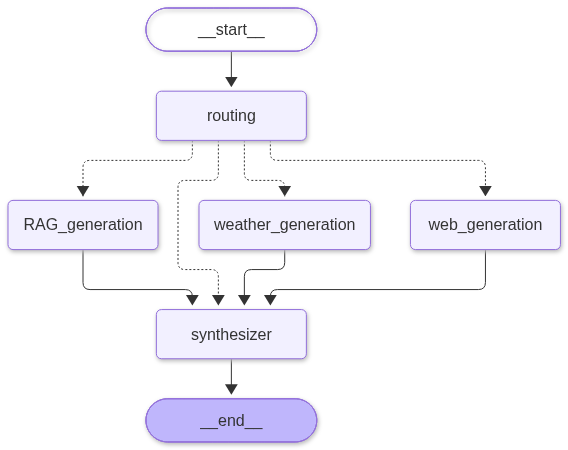

In [ ]:
# # Build the graph 

# %%
graph = StateGraph(ResearchAssistant)

#Nodes 
graph.add_node(routing)
graph.add_node(weather_generation)
graph.add_node(web_generation)
graph.add_node(RAG_generation)
graph.add_node(synthesizer)
 

#edges 

graph.add_edge(START,"routing")
graph.add_conditional_edges("routing",selectSpecialist, ["weather_generation","web_generation","RAG_generation","synthesizer"])
graph.add_edge("weather_generation","synthesizer")
graph.add_edge("web_generation","synthesizer")
graph.add_edge("RAG_generation","synthesizer")
graph.add_edge("synthesizer",END)

graph = graph.compile()
graph 
               

In [ ]:
try:
    response = graph.invoke(initial_state)
    print(response["synthesizer"])
except Exception as e: 
    print(f"Error. {e}")


**1. Weather in Peoria (Illinois) – Current conditions**  
- **Temperature:** 285 K ≈ **12 °C** (≈ 53 °F)  
- **Feels like:** 284.6 K ≈ 11 °C (52 °F)  
- **Sky:** *overcast clouds* (100 % cloud cover)  
- **Humidity:** 87 %  
- **Wind:** 3.6 m s⁻¹ (≈ 8 mph) from 230° (south‑west)  
- **Pressure:** 1007 hPa  
- **Visibility:** 10 km  

These figures come from the OpenWeatherMap API response for Peoria, IL [Weather evidence].  

*What you can expect:* The sky is completely clouded over with a chance of light rain later in the day (the 30‑day forecast from a local site also notes “light rain likely” and a temperature around 20 °C later this morning) [Web evidence – aqi.in].

---

**2. Top U.S. news today (Nov 4 2026)**  

| Category | Headline (summary) | Source |
|----------|-------------------|--------|
| **Politics / Elections** | *Midterm Election Day is underway. All 435 House seats and 35 Senate seats are on the ballot. Republicans currently hold a 53‑47 Senate majority and a narrow

# testing code

In [ ]:
query = "What is LangGraph?"
result = graph.invoke({"user_query": query})

print("Routes:", result["routing"])
print("RAG answer:", result.get("RAG_generation"))
print("Final answer:", result["synthesizer"])

Routes: ['RAG']
RAG answer: **LangGraph** is a framework built on top of LangChain that provides the core capabilities needed for orchestrating AI agents and building complex, reusable workflows.  

Key points:

* **Agent‑orchestration focus** – It handles durable execution, streaming, human‑in‑the‑loop interaction, and other infrastructure concerns that make long‑running or multi‑step agents reliable.  
* **Hybrid graphs** – A LangGraph graph can combine deterministic, rule‑based steps with LLM‑driven, agentic steps in the same workflow. This lets you design pipelines where the predictable parts are auditable and the flexible parts can leverage a language model’s reasoning.  
* **Fine‑grained control** – By mixing these step types you decide exactly where and how AI is applied, giving you both transparency and the expressive power of LLMs.

In short, LangGraph is the “orchestration layer” of the LangChain ecosystem, enabling durable, streaming, and human‑in‑the‑loop agent workflows th

In [ ]:
query = "What is the weather in Peoria, Illinois? What is LangGraph?"
result = graph.invoke({"user_query": query})

print("Routes:", result["routing"])
print("RAG answer:", result.get("RAG_generation"))
print("Final answer:", result["synthesizer"])

Routes: ['weather', 'RAG']
RAG answer: **What is LangGraph?**

LangGraph is a library designed for building and orchestrating complex, state‑ful workflows that combine deterministic logic with LLM‑driven (agentic) steps. Its core capabilities focus on:

- **Durable execution** – workflows can be paused, resumed, and persisted across sessions.  
- **Streaming** – intermediate results can be streamed back to callers, enabling real‑time feedback.  
- **Human‑in‑the‑loop** – it provides hooks for manual interventions or approvals at any step.  
- **Mixed deterministic & agentic steps** – you can embed predictable code (e.g., data validation, API calls) alongside flexible, model‑driven actions, giving fine‑grained control over where AI is applied.

By mixing these elements in a single graph, LangGraph lets developers construct bespoke AI‑augmented pipelines that are both auditable and adaptable, making it especially useful for applications that need reliable orchestration of multiple LLM ca

In [ ]:
query = "What is the weather in Peoria, Illinois? What are today’s top U.S. news stories? What is LangGraph?"
result = graph.invoke({"user_query": query})

print("Routes:", result["routing"])
print("RAG answer:", result.get("RAG_generation"))
print("Final answer:", result["synthesizer"])

Routes: ['weather', 'web', 'RAG']
RAG answer: **LangGraph**

LangGraph is a framework that builds on LangChain to enable sophisticated agent orchestration. Its core focus is on providing the infrastructure needed for durable, streaming, and human‑in‑the‑loop execution of AI workflows. By allowing deterministic steps to be combined with LLM‑driven, agentic steps within a single graph, LangGraph lets developers create custom pipelines where some parts are fully predictable and auditable while others remain flexible and model‑driven. This fine‑grained control over where and how AI is applied makes it especially useful for building complex, multi‑step applications that require both reliable logic and adaptable language‑model reasoning.
Final answer: **Weather in Peoria, Illinois (as of Nov 4 2026)**  
- **Temperature:** ≈ 12 °C (≈ 55 °F) – the OpenWeatherMap payload reports 284.9 K (≈ 11.8 °C) and the WeatherAPI feed lists 12.8 °C (55.1 °F).  
- **Conditions:** Overcast/mostly cloudy (clou

In [ ]:
query = "US midterm election results 2026"
result = graph.invoke({"user_query": query})

print("Routes:", result["routing"])
print("RAG answer:", result.get("RAG_generation"))
print("Final answer:", result["synthesizer"])

Routes: ['web']
RAG answer: None
Final answer: **2026 U.S. Midterm Election – What the results look like**

| Chamber | Result | What it means |
|---------|--------|----------------|
| **U.S. House of Representatives** | **Democrats win a narrow majority (218 seats)** – the party needed exactly 218 seats to control the chamber. | After the November 3 vote, the Democrats secured enough seats to take back the House, which had been held by Republicans after the 2024 elections. |
| **U.S. Senate** | **Democrats win a slim majority (≥ 54 seats)** – the final tally gave the Democrats at least 54 of the 100 seats, enough for a majority. | The win flips several key Senate races, most notably a seat in North Carolina that was captured by Democrat **Roy Cooper** (see Reuters). The new Democratic caucus will control both chambers for the remainder of President Donald Trump’s term. |

### Key points from the coverage

* **Early voting:** More than 57 million early votes were cast nationwide, surpa